In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt 
from sklearn.model_selection import train_test_split
import math

#### Data Collection and Loading

In [2]:
df_customers = pd.read_csv("data/customers.csv")
df_loans = pd.read_csv("data/loans.csv")
df_bureau = pd.read_csv("data/bureau_data.csv")

In [3]:
df_customers.shape, df_loans.shape, df_bureau.shape

((50000, 12), (50000, 15), (50000, 8))

In [4]:
df = pd.merge(df_customers, df_loans, how="inner", on="cust_id")
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,loan_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,disbursal_date,installment_start_dt,default
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2467000,49340.0,444060,1973600,33,1630408,873386,2019-07-24,2019-08-10,False
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,3883000,77660.0,698940,3106400,30,709309,464100,2019-07-24,2019-08-15,False
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2170000,43400.0,390600,1736000,21,1562399,1476042,2019-07-24,2019-08-21,False
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,1747000,34940.0,314460,1397600,6,1257839,1031094,2019-07-24,2019-08-09,False
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,4520000,90400.0,813600,3616000,28,1772334,1032458,2019-07-24,2019-08-02,False


In [5]:
df = pd.merge(df, df_bureau, how="inner", on="cust_id")
df.shape

(50000, 33)

In [6]:
df.head()

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,default,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio
0,C00001,44,M,Married,Self-Employed,2586000,3,Owned,27,Delhi,...,2019-07-24,2019-08-10,False,1,1,42,0,0,3,7
1,C00002,38,M,Married,Salaried,1206000,3,Owned,4,Chennai,...,2019-07-24,2019-08-15,False,3,1,96,12,60,5,4
2,C00003,46,F,Married,Self-Employed,2878000,3,Owned,24,Kolkata,...,2019-07-24,2019-08-21,False,2,1,82,24,147,6,58
3,C00004,55,F,Single,Self-Employed,3547000,1,Owned,15,Bangalore,...,2019-07-24,2019-08-09,False,3,0,115,15,87,5,26
4,C00005,37,M,Married,Salaried,3432000,3,Owned,28,Pune,...,2019-07-24,2019-08-02,False,4,2,120,0,0,5,10


In [7]:
df.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'default',
       'number_of_open_accounts', 'number_of_closed_accounts',
       'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count',
       'credit_utilization_ratio'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      50000 non-null  str    
 1   age                          50000 non-null  int64  
 2   gender                       50000 non-null  str    
 3   marital_status               50000 non-null  str    
 4   employment_status            50000 non-null  str    
 5   income                       50000 non-null  int64  
 6   number_of_dependants         50000 non-null  int64  
 7   residence_type               49938 non-null  str    
 8   years_at_current_address     50000 non-null  int64  
 9   city                         50000 non-null  str    
 10  state                        50000 non-null  str    
 11  zipcode                      50000 non-null  int64  
 12  loan_id                      50000 non-null  str    
 13  loan_purpose               

In [9]:
df['default'] = df['default'].astype(int)
df['default'].value_counts()

default
0    45703
1     4297
Name: count, dtype: int64

- Performing train-test split to avoid data leakage

In [10]:
X = df.drop('default', axis=1)
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

In [11]:
df_train = pd.concat([X_train, y_train], axis=1)
df_test = pd.concat([X_test, y_test], axis=1)

In [12]:
df_train.shape, df_test.shape

((37500, 33), (12500, 33))

In [13]:
df_train.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,2022-04-21,2022-05-21,4,2,90,6,33,8,59,0
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,2020-11-24,2020-12-11,3,1,119,4,17,4,92,0
883,C00884,50,F,Single,Self-Employed,2891000,0,Mortgage,29,Lucknow,...,2019-08-25,2019-09-19,2,1,83,14,78,4,83,0


In [14]:
df_test.head(3)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
33553,C33554,36,F,Married,Self-Employed,3373000,3,Owned,15,Hyderabad,...,2022-11-30,2022-12-21,2,2,70,3,27,5,12,0
9427,C09428,33,F,Single,Salaried,2725000,0,Owned,15,Jaipur,...,2020-07-02,2020-07-15,4,0,115,0,0,9,85,0
199,C00200,28,M,Single,Self-Employed,1071000,0,Owned,19,Delhi,...,2019-07-31,2019-08-02,4,1,144,0,0,4,72,0


#### Data Cleaning

In [15]:
df_train.isna().sum()

cust_id                         0
age                             0
gender                          0
marital_status                  0
employment_status               0
income                          0
number_of_dependants            0
residence_type                 48
years_at_current_address        0
city                            0
state                           0
zipcode                         0
loan_id                         0
loan_purpose                    0
loan_type                       0
sanction_amount                 0
loan_amount                     0
processing_fee                  0
gst                             0
net_disbursement                0
loan_tenure_months              0
principal_outstanding           0
bank_balance_at_application     0
disbursal_date                  0
installment_start_dt            0
number_of_open_accounts         0
number_of_closed_accounts       0
total_loan_months               0
delinquent_months               0
total_dpd     

In [16]:
df_train['residence_type'].unique()

<ArrowStringArray>
['Owned', 'Mortgage', 'Rented', nan]
Length: 4, dtype: str

In [17]:
mode_residence_type = df_train['residence_type'].mode()[0]
mode_residence_type

'Owned'

In [18]:
df_train.fillna({
    'residence_type': mode_residence_type
}, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,2022-04-21,2022-05-21,4,2,90,6,33,8,59,0
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,2020-11-24,2020-12-11,3,1,119,4,17,4,92,0
883,C00884,50,F,Single,Self-Employed,2891000,0,Mortgage,29,Lucknow,...,2019-08-25,2019-09-19,2,1,83,14,78,4,83,0
7303,C07304,43,F,Single,Self-Employed,272000,1,Owned,27,Bangalore,...,2020-04-16,2020-05-05,1,1,37,0,0,5,34,0
45124,C45125,31,F,Single,Salaried,141000,0,Owned,27,Jaipur,...,2024-01-26,2024-02-17,2,0,62,6,28,5,19,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,C11285,33,F,Single,Salaried,3506000,0,Rented,31,Hyderabad,...,2020-09-08,2020-09-17,4,1,129,23,126,7,93,1
44732,C44733,33,F,Single,Salaried,3889000,0,Owned,26,Delhi,...,2024-01-12,2024-01-21,3,0,80,0,0,3,23,0
38158,C38159,35,M,Married,Self-Employed,2420000,3,Rented,5,Kolkata,...,2023-05-17,2023-06-14,1,2,8,0,0,2,53,0
860,C00861,42,F,Married,Salaried,2133000,4,Owned,6,Mumbai,...,2019-08-25,2019-09-12,3,1,130,5,24,7,17,0


In [19]:
df_train.isna().sum()

cust_id                        0
age                            0
gender                         0
marital_status                 0
employment_status              0
income                         0
number_of_dependants           0
residence_type                 0
years_at_current_address       0
city                           0
state                          0
zipcode                        0
loan_id                        0
loan_purpose                   0
loan_type                      0
sanction_amount                0
loan_amount                    0
processing_fee                 0
gst                            0
net_disbursement               0
loan_tenure_months             0
principal_outstanding          0
bank_balance_at_application    0
disbursal_date                 0
installment_start_dt           0
number_of_open_accounts        0
number_of_closed_accounts      0
total_loan_months              0
delinquent_months              0
total_dpd                      0
enquiry_co

In [20]:
df_test.fillna({
    "residence_type": mode_residence_type
}, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
33553,C33554,36,F,Married,Self-Employed,3373000,3,Owned,15,Hyderabad,...,2022-11-30,2022-12-21,2,2,70,3,27,5,12,0
9427,C09428,33,F,Single,Salaried,2725000,0,Owned,15,Jaipur,...,2020-07-02,2020-07-15,4,0,115,0,0,9,85,0
199,C00200,28,M,Single,Self-Employed,1071000,0,Owned,19,Delhi,...,2019-07-31,2019-08-02,4,1,144,0,0,4,72,0
12447,C12448,28,M,Married,Salaried,1183000,3,Rented,4,Delhi,...,2020-10-20,2020-10-31,3,2,93,0,0,4,90,0
39489,C39490,52,M,Married,Self-Employed,2079000,2,Owned,26,Pune,...,2023-07-05,2023-08-02,4,2,152,20,105,9,53,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9771,C09772,42,F,Married,Salaried,448000,2,Owned,29,Kolkata,...,2020-07-15,2020-07-22,2,1,42,7,48,4,19,0
34737,C34738,40,F,Married,Self-Employed,2403000,3,Mortgage,11,Chennai,...,2023-01-12,2023-01-14,3,1,109,0,0,5,17,0
30390,C30391,35,M,Single,Self-Employed,1631000,0,Mortgage,11,Ahmedabad,...,2022-08-06,2022-09-03,1,1,44,0,0,4,27,0
6797,C06798,55,M,Married,Self-Employed,755000,4,Owned,14,Chennai,...,2020-03-28,2020-04-19,3,1,92,5,32,6,16,0


In [21]:
df_test.isna().sum()

cust_id                        0
age                            0
gender                         0
marital_status                 0
employment_status              0
income                         0
number_of_dependants           0
residence_type                 0
years_at_current_address       0
city                           0
state                          0
zipcode                        0
loan_id                        0
loan_purpose                   0
loan_type                      0
sanction_amount                0
loan_amount                    0
processing_fee                 0
gst                            0
net_disbursement               0
loan_tenure_months             0
principal_outstanding          0
bank_balance_at_application    0
disbursal_date                 0
installment_start_dt           0
number_of_open_accounts        0
number_of_closed_accounts      0
total_loan_months              0
delinquent_months              0
total_dpd                      0
enquiry_co

In [22]:
df_train.duplicated().sum()

np.int64(0)

In [23]:
df_test.duplicated().sum()

np.int64(0)

In [24]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 37500 entries, 27434 to 15795
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   cust_id                      37500 non-null  str    
 1   age                          37500 non-null  int64  
 2   gender                       37500 non-null  str    
 3   marital_status               37500 non-null  str    
 4   employment_status            37500 non-null  str    
 5   income                       37500 non-null  int64  
 6   number_of_dependants         37500 non-null  int64  
 7   residence_type               37500 non-null  str    
 8   years_at_current_address     37500 non-null  int64  
 9   city                         37500 non-null  str    
 10  state                        37500 non-null  str    
 11  zipcode                      37500 non-null  int64  
 12  loan_id                      37500 non-null  str    
 13  loan_purpose                

In [25]:
numeric_cols = ['age', 'income', 'number_of_dependants', 'years_at_current_address',
       'sanction_amount', 'loan_amount', 'processing_fee', 'gst',
       'net_disbursement', 'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio']

In [26]:
categorical_cols = ['gender', 'marital_status', 'employment_status',
       'residence_type', 'city', 'state', 'loan_purpose',
       'loan_type']

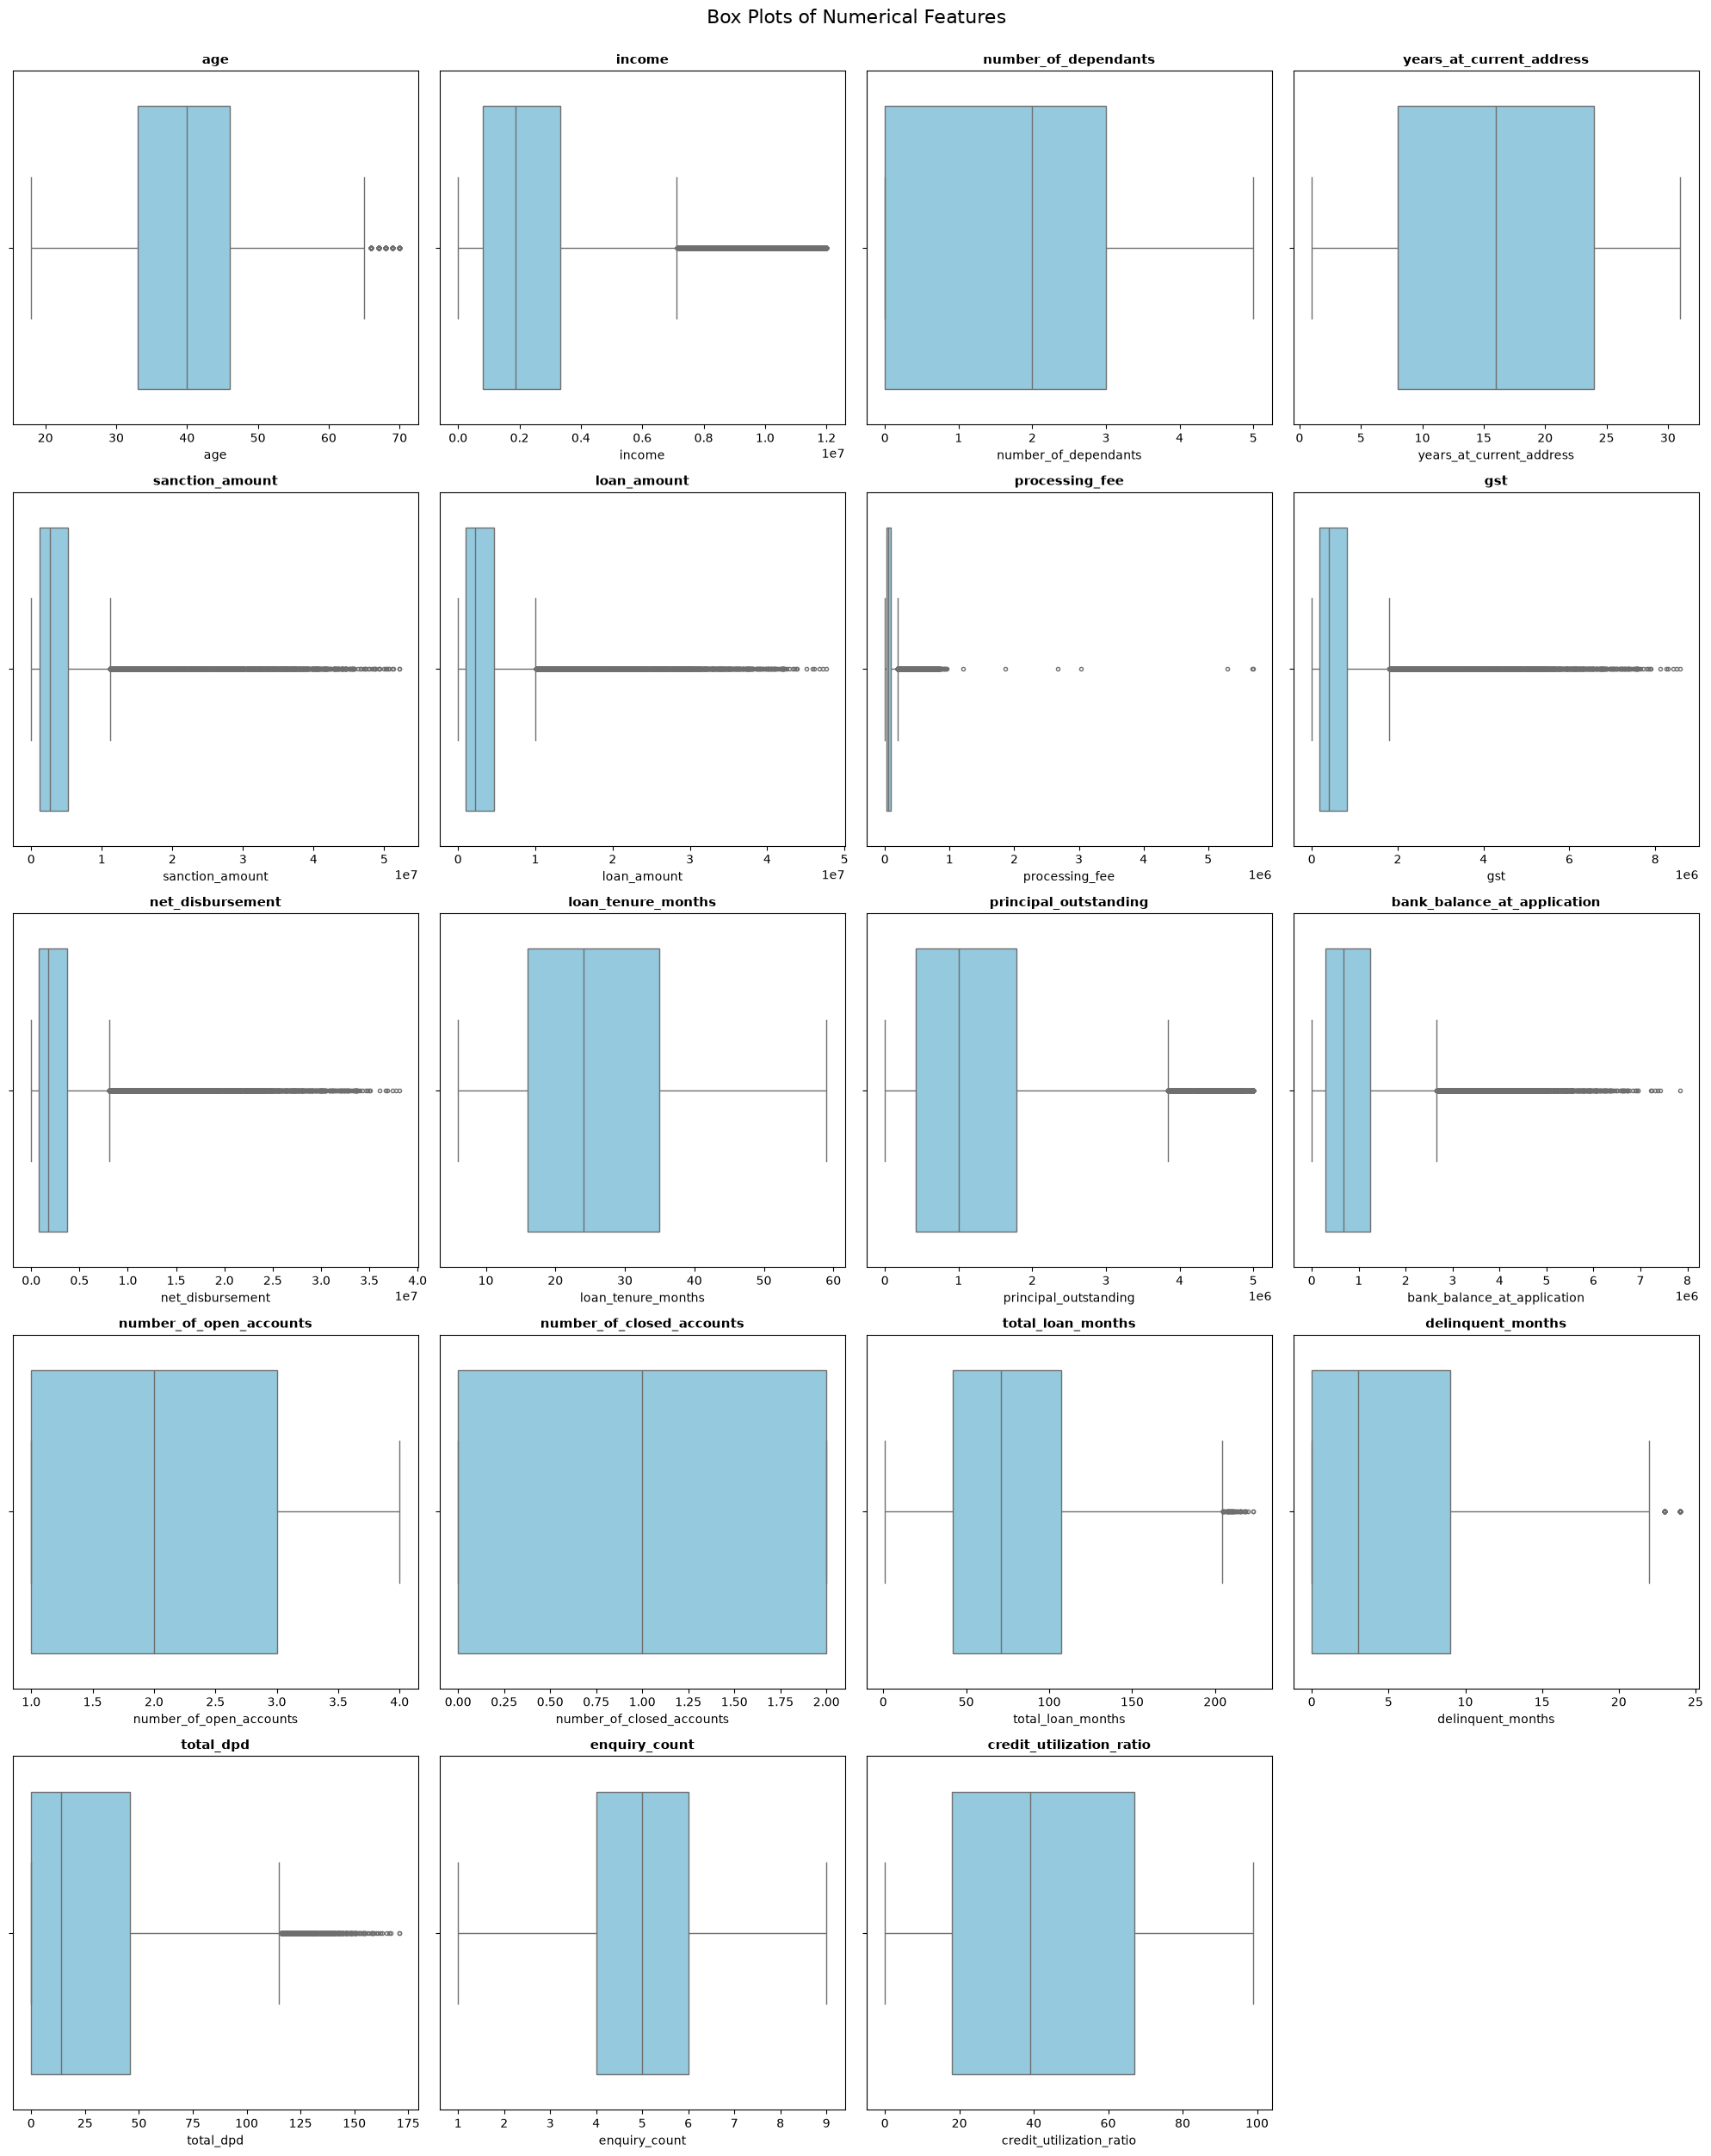

In [27]:
# Box Plot
n_cols = 4               
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 5))
axes = axes.flatten()
 
for i, col in enumerate(numeric_cols):
    sns.boxplot(x=df_train[col], ax=axes[i], color="skyblue", fliersize=3)
    axes[i].set_title(col, fontsize=11, fontweight="bold")
 
# Hide any unused subplots in the last row
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
 
plt.suptitle("Box Plots of Numerical Features", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

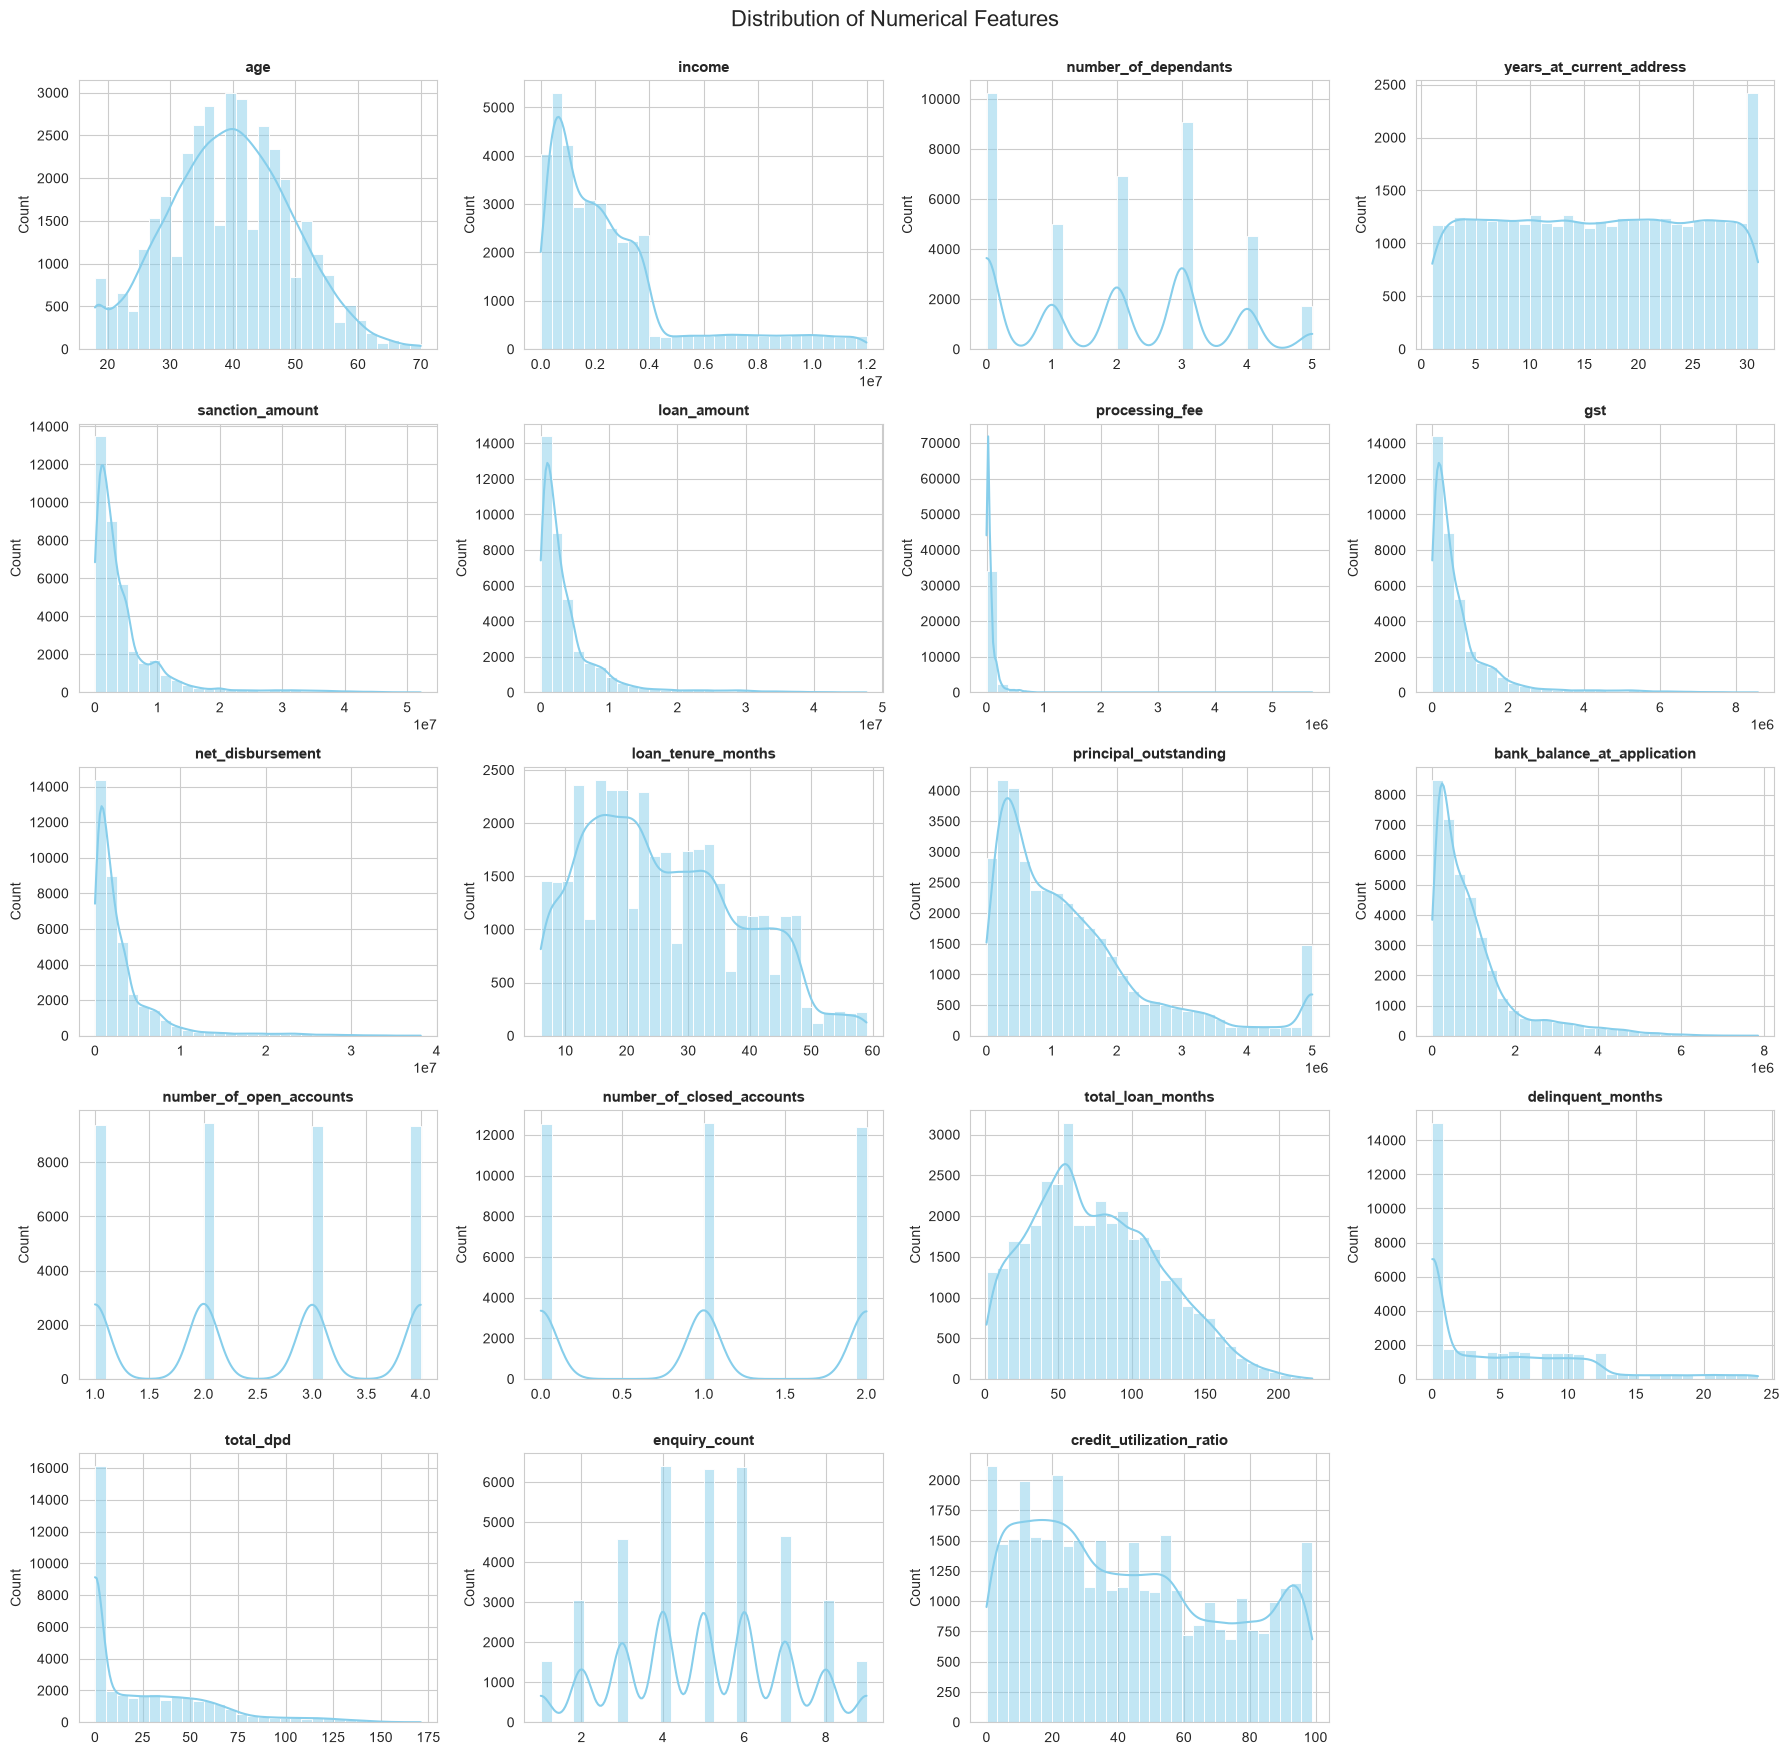

In [28]:
# Hist Plot
n_cols = 4                                   # plots per row (change as needed, keep >= 4)
n_rows = math.ceil(len(numeric_cols) / n_cols)
 
sns.set_style("whitegrid")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4.5, n_rows * 3.5))
axes = axes.flatten()
 
for ax, col in zip(axes, numeric_cols):
    sns.histplot(data=df_train, x=col, bins=30, kde=True, color="skyblue", ax=ax)
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Count")
 
# Hide any unused subplots in the last row
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
 
plt.suptitle("Distribution of Numerical Features", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

In [29]:
df_train['processing_fee'].describe()

count    3.750000e+04
mean     8.072411e+04
std      1.208307e+05
min      0.000000e+00
25%      1.918000e+04
50%      4.470000e+04
75%      9.200000e+04
max      5.698030e+06
Name: processing_fee, dtype: float64

In [30]:
df_train['gst'].describe()

count    3.750000e+04
mean     7.205034e+05
std      9.721624e+05
min      0.000000e+00
25%      1.726200e+05
50%      4.021200e+05
75%      8.275050e+05
max      8.580060e+06
Name: gst, dtype: float64

In [31]:
df_train[df_train['processing_fee'] == df_train['processing_fee'].max()]

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
12294,C12295,49,M,Married,Salaried,3504000,2,Rented,24,Ahmedabad,...,2020-10-15,2020-10-23,1,2,58,0,0,3,86,0


In [32]:
df_train[df_train['processing_fee'] > df_train['loan_amount']]

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
23981,C23982,33,F,Single,Self-Employed,1790000,0,Rented,7,Kolkata,...,2021-12-15,2022-01-14,4,2,154,9,31,6,26,0
9898,C09899,56,M,Married,Self-Employed,8948000,5,Owned,16,Ahmedabad,...,2020-07-19,2020-08-11,2,1,51,1,5,3,92,0
47089,C47090,37,M,Married,Self-Employed,1892000,2,Rented,13,Jaipur,...,2024-04-07,2024-04-15,3,0,112,5,33,3,32,0
33705,C33706,54,M,Married,Self-Employed,10763000,2,Mortgage,5,Ahmedabad,...,2022-12-05,2022-12-30,3,1,140,0,0,5,47,0
12294,C12295,49,M,Married,Salaried,3504000,2,Rented,24,Ahmedabad,...,2020-10-15,2020-10-23,1,2,58,0,0,3,86,0
28174,C28175,36,F,Single,Self-Employed,1123000,1,Rented,31,Hyderabad,...,2022-05-18,2022-06-05,3,0,111,8,41,3,62,0
29305,C29306,52,M,Married,Self-Employed,3839000,2,Owned,11,Delhi,...,2022-06-28,2022-07-21,2,2,42,11,65,3,2,0


In [33]:
df_train_1 = df_train[(df_train.processing_fee / df_train.loan_amount) < 0.03].copy()
df_train_1.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,2022-04-21,2022-05-21,4,2,90,6,33,8,59,0
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,2020-11-24,2020-12-11,3,1,119,4,17,4,92,0


In [34]:
df_train_1[(df_train_1.processing_fee / df_train_1.loan_amount) > 0.03]

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default


In [35]:
df_test_1 = df_test[(df_test.processing_fee / df_test.loan_amount) < 0.03].copy()

In [36]:
for col in categorical_cols:
    print(f"{col} --> {df_train_1[col].unique()}")

gender --> <ArrowStringArray>
['F', 'M']
Length: 2, dtype: str
marital_status --> <ArrowStringArray>
['Single', 'Married']
Length: 2, dtype: str
employment_status --> <ArrowStringArray>
['Salaried', 'Self-Employed']
Length: 2, dtype: str
residence_type --> <ArrowStringArray>
['Owned', 'Mortgage', 'Rented']
Length: 3, dtype: str
city --> <ArrowStringArray>
['Ahmedabad',     'Delhi',   'Lucknow', 'Bangalore',    'Jaipur', 'Hyderabad',
   'Kolkata',      'Pune',   'Chennai',    'Mumbai']
Length: 10, dtype: str
state --> <ArrowStringArray>
[      'Gujarat',         'Delhi', 'Uttar Pradesh',     'Karnataka',
     'Rajasthan',     'Telangana',   'West Bengal',   'Maharashtra',
    'Tamil Nadu']
Length: 9, dtype: str
loan_purpose --> <ArrowStringArray>
['Home', 'Auto', 'Personal', 'Education', 'Personaal']
Length: 5, dtype: str
loan_type --> <ArrowStringArray>
['Secured', 'Unsecured']
Length: 2, dtype: str


In [37]:
df_train_1['loan_purpose'].value_counts()

loan_purpose
Personal     13136
Home         11271
Auto          7437
Education     5626
Personaal       17
Name: count, dtype: int64

In [38]:
df_train_1.replace({
    'loan_purpose': {'Personaal': 'Personal'}
}, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,2022-04-21,2022-05-21,4,2,90,6,33,8,59,0
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,2020-11-24,2020-12-11,3,1,119,4,17,4,92,0
883,C00884,50,F,Single,Self-Employed,2891000,0,Mortgage,29,Lucknow,...,2019-08-25,2019-09-19,2,1,83,14,78,4,83,0
7303,C07304,43,F,Single,Self-Employed,272000,1,Owned,27,Bangalore,...,2020-04-16,2020-05-05,1,1,37,0,0,5,34,0
45124,C45125,31,F,Single,Salaried,141000,0,Owned,27,Jaipur,...,2024-01-26,2024-02-17,2,0,62,6,28,5,19,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,C11285,33,F,Single,Salaried,3506000,0,Rented,31,Hyderabad,...,2020-09-08,2020-09-17,4,1,129,23,126,7,93,1
44732,C44733,33,F,Single,Salaried,3889000,0,Owned,26,Delhi,...,2024-01-12,2024-01-21,3,0,80,0,0,3,23,0
38158,C38159,35,M,Married,Self-Employed,2420000,3,Rented,5,Kolkata,...,2023-05-17,2023-06-14,1,2,8,0,0,2,53,0
860,C00861,42,F,Married,Salaried,2133000,4,Owned,6,Mumbai,...,2019-08-25,2019-09-12,3,1,130,5,24,7,17,0


In [39]:
df_train_1['loan_purpose'].value_counts()

loan_purpose
Personal     13153
Home         11271
Auto          7437
Education     5626
Name: count, dtype: int64

In [40]:
df_test_1.replace({
    'loan_purpose': {'Personaal': 'Personal'}
}, inplace=True)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default
33553,C33554,36,F,Married,Self-Employed,3373000,3,Owned,15,Hyderabad,...,2022-11-30,2022-12-21,2,2,70,3,27,5,12,0
9427,C09428,33,F,Single,Salaried,2725000,0,Owned,15,Jaipur,...,2020-07-02,2020-07-15,4,0,115,0,0,9,85,0
199,C00200,28,M,Single,Self-Employed,1071000,0,Owned,19,Delhi,...,2019-07-31,2019-08-02,4,1,144,0,0,4,72,0
12447,C12448,28,M,Married,Salaried,1183000,3,Rented,4,Delhi,...,2020-10-20,2020-10-31,3,2,93,0,0,4,90,0
39489,C39490,52,M,Married,Self-Employed,2079000,2,Owned,26,Pune,...,2023-07-05,2023-08-02,4,2,152,20,105,9,53,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9771,C09772,42,F,Married,Salaried,448000,2,Owned,29,Kolkata,...,2020-07-15,2020-07-22,2,1,42,7,48,4,19,0
34737,C34738,40,F,Married,Self-Employed,2403000,3,Mortgage,11,Chennai,...,2023-01-12,2023-01-14,3,1,109,0,0,5,17,0
30390,C30391,35,M,Single,Self-Employed,1631000,0,Mortgage,11,Ahmedabad,...,2022-08-06,2022-09-03,1,1,44,0,0,4,27,0
6797,C06798,55,M,Married,Self-Employed,755000,4,Owned,14,Chennai,...,2020-03-28,2020-04-19,3,1,92,5,32,6,16,0


In [41]:
df_train_1[(df_train_1['gst'] / df_train_1['loan_amount']) > 0.18]

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default


In [42]:
df_train_1[df_train_1['loan_amount'] > df_train_1.sanction_amount]

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,disbursal_date,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default


#### Exploratory Data Analysis

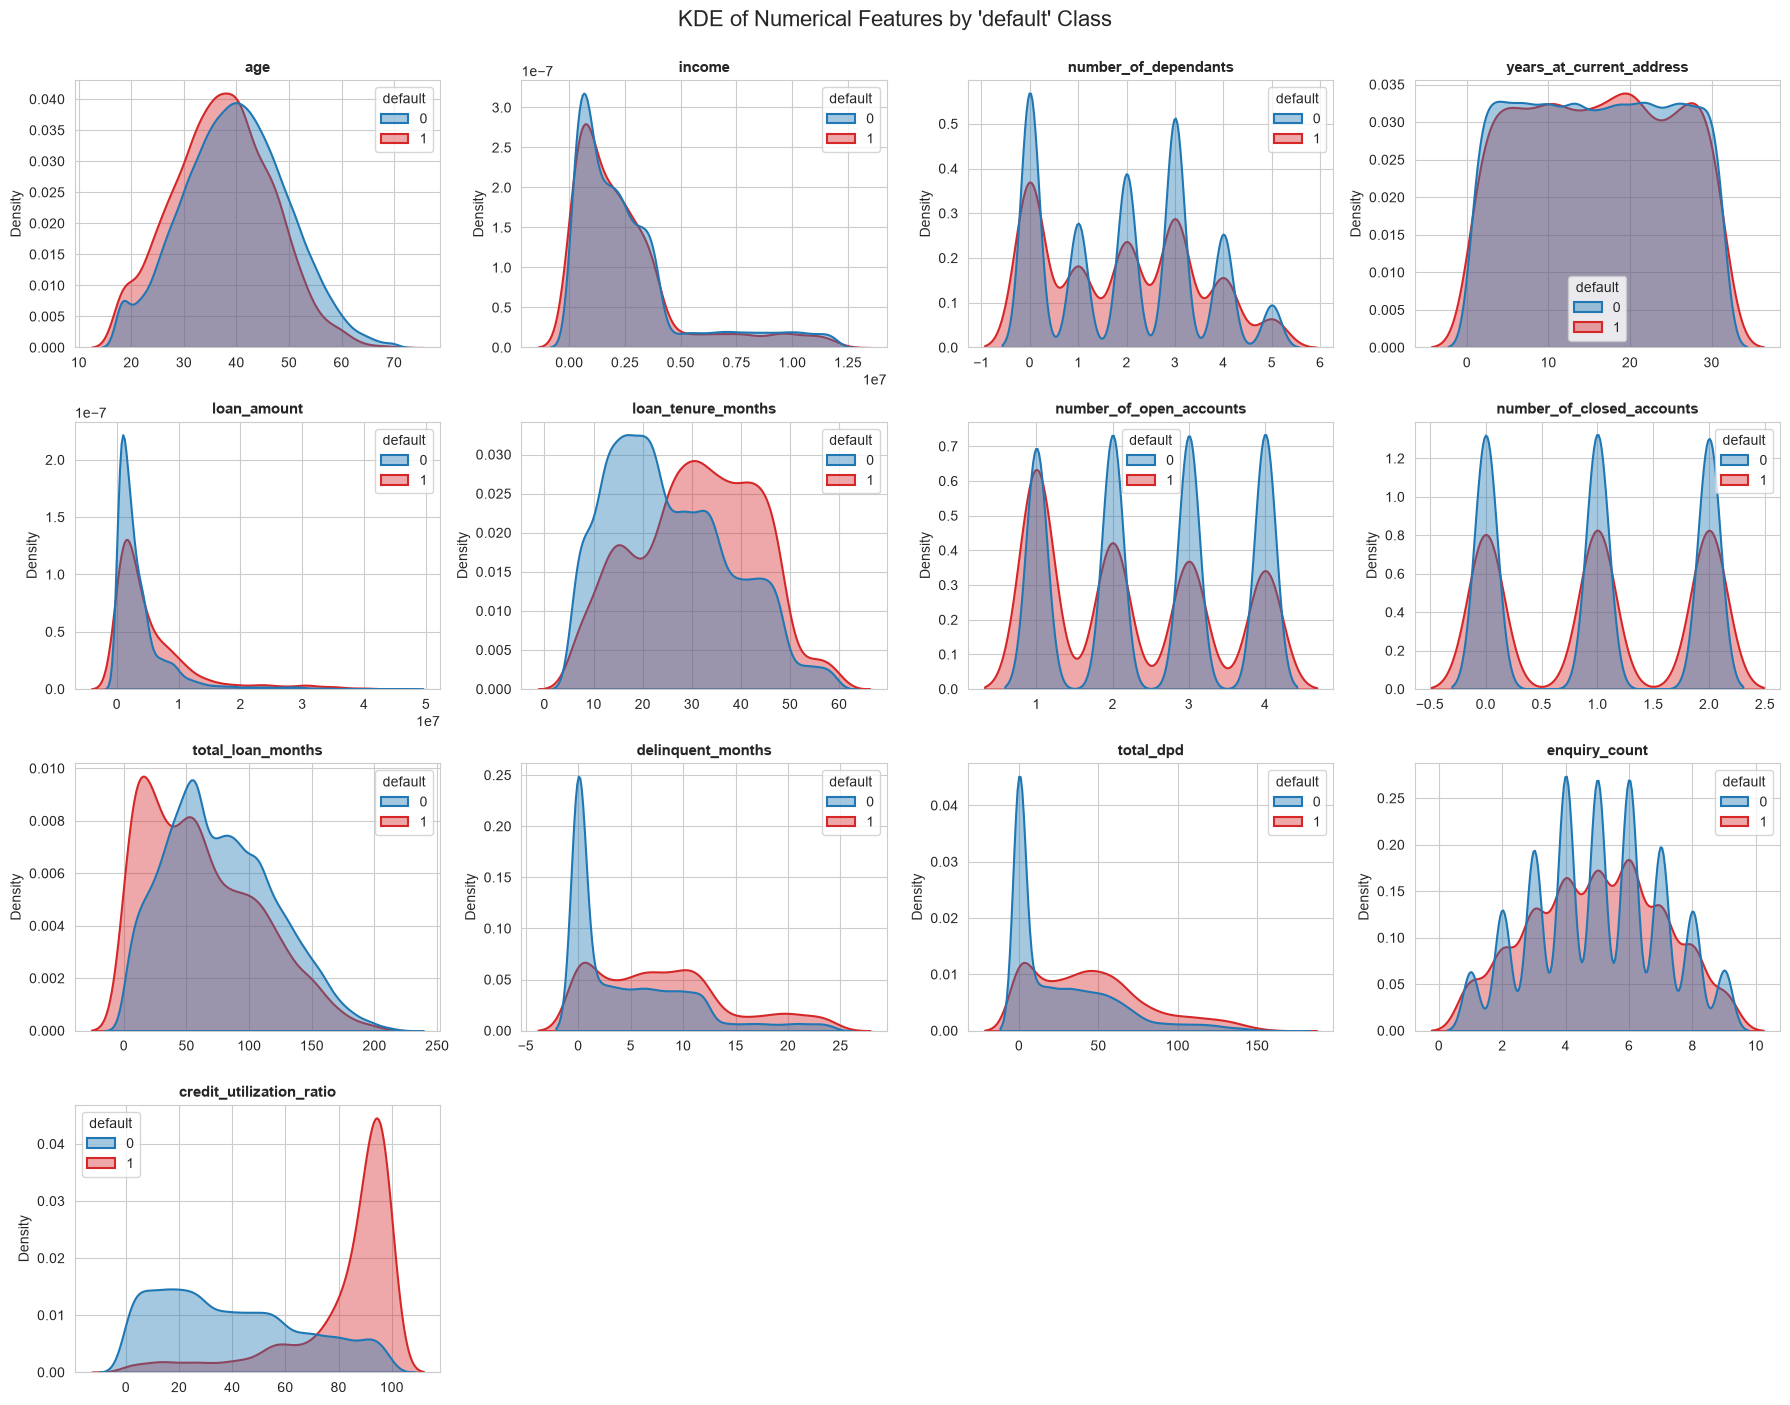

In [43]:
target = 'default'
numeric_cols = ['age', 'income', 'number_of_dependants', 'years_at_current_address', 'loan_amount',
'loan_tenure_months', 'number_of_open_accounts', 'number_of_closed_accounts', 'total_loan_months', 'delinquent_months', 'total_dpd', 'enquiry_count', 'credit_utilization_ratio']
 
n_cols = 4                                  
n_rows = math.ceil(len(numeric_cols) / n_cols)
 
sns.set_style("whitegrid")
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4.5, n_rows * 3.5))
axes = axes.flatten()
 
for ax, col in zip(axes, numeric_cols):
    sns.kdeplot(
        data=df_train_1,
        x=col,
        hue=target,
        fill=True,
        common_norm=False,       # scale each class's density independently
        palette={0: "tab:blue", 1: "tab:red"},
        alpha=0.4,
        linewidth=1.5,
        warn_singular=False,     # silence warnings for near-constant columns
        ax=ax,
    )
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Density")
 
# Hide any unused subplots in the last row
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
 
plt.suptitle(f"KDE of Numerical Features by '{target}' Class", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

- Insights
1. Columns: total_dpd, delinquent_months, total_loan_months, credit_utilization_ratio, loan_tenure_months have higher values for the default class indicating high likelyhood for being a defaulter becoming strong predictors.
2. Remaining columns doesn't show much affect.

#### Feature Engineering and Feature Selection

In [44]:
df_train_1['loan_to_income'] = round(df_train_1.loan_amount / df_train_1.income, 2)
df_train_1.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,installment_start_dt,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,2022-05-21,4,2,90,6,33,8,59,0,2.90
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,2020-12-11,3,1,119,4,17,4,92,0,1.08


In [45]:
df_train_1['loan_to_income'].describe()

count    37487.000000
mean         1.554890
std          0.972907
min          0.300000
25%          0.770000
50%          1.160000
75%          2.450000
max          4.570000
Name: loan_to_income, dtype: float64

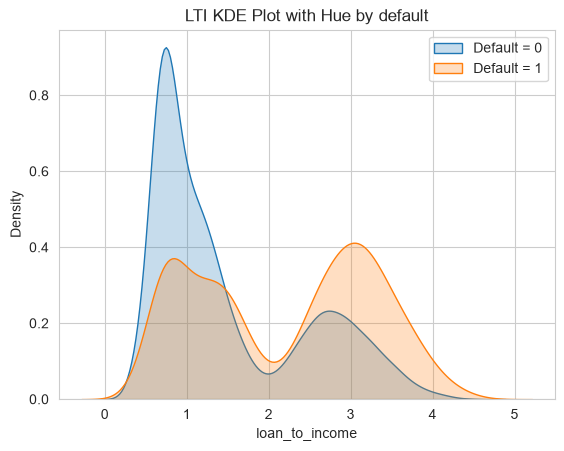

In [46]:
sns.kdeplot(df_train_1[df_train_1['default'] == 0]['loan_to_income'], fill=True, label="Default = 0")
sns.kdeplot(df_train_1[df_train_1['default'] == 1]['loan_to_income'], fill=True, label="Default = 1")
plt.title(f"LTI KDE Plot with Hue by default")
plt.legend()
plt.show()

In [47]:
df_test_1['loan_to_income'] = round(df_test_1.loan_amount / df_test_1.income, 2)

In [48]:
df_train_1["delinquency_ratio"] = round(100 * df_train_1.delinquent_months / df_train_1.total_loan_months, 2)
df_train_1.head(2)

,cust_id,age,gender,marital_status,employment_status,income,number_of_dependants,residence_type,years_at_current_address,city,...,number_of_open_accounts,number_of_closed_accounts,total_loan_months,delinquent_months,total_dpd,enquiry_count,credit_utilization_ratio,default,loan_to_income,delinquency_ratio
27434,C27435,45,F,Single,Salaried,1131000,0,Owned,5,Ahmedabad,...,4,2,90,6,33,8,59,0,2.90,6.67
13400,C13401,29,M,Single,Salaried,2343000,0,Owned,25,Delhi,...,3,1,119,4,17,4,92,0,1.08,3.36


In [49]:
df_test_1["delinquency_ratio"] = round(100 * df_test_1.delinquent_months / df_test_1.total_loan_months, 2)

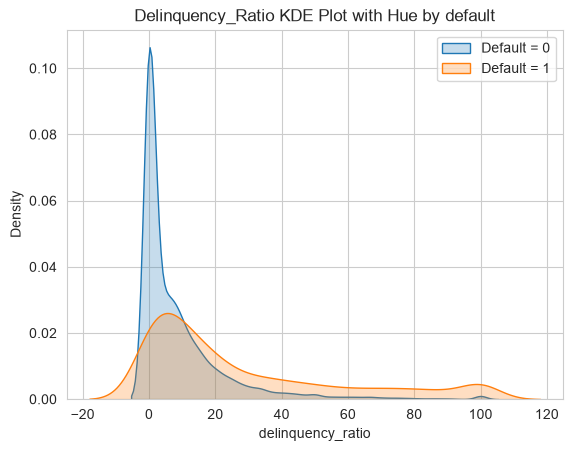

In [50]:
sns.kdeplot(df_train_1[df_train_1['default'] == 0]['delinquency_ratio'], fill=True, label="Default = 0")
sns.kdeplot(df_train_1[df_train_1['default'] == 1]['delinquency_ratio'], fill=True, label="Default = 1")
plt.title(f"Delinquency_Ratio KDE Plot with Hue by default")
plt.legend()
plt.show()

In [51]:
df_train_1['avg_dpd_per_delinquency'] = np.where(
df_train_1['delinquent_months'] != 0,
round(df_train_1['total_dpd'] / df_train_1['delinquent_months'], 2),
0
)

In [52]:
df_train_1['avg_dpd_per_delinquency'].describe()

count    37487.000000
mean         3.294614
std          2.903345
min          0.000000
25%          0.000000
50%          4.330000
75%          5.750000
max         10.000000
Name: avg_dpd_per_delinquency, dtype: float64

In [53]:
df_test_1['avg_dpd_per_delinquency'] = np.where(
df_test_1['delinquent_months'] != 0,
round(df_test_1['total_dpd'] / df_test_1['delinquent_months'], 2),
0
)

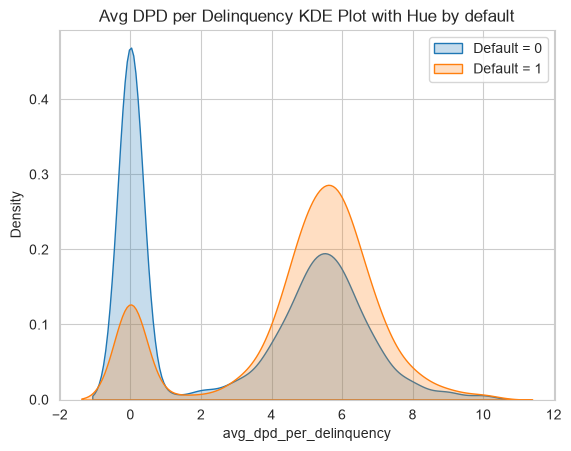

In [54]:
sns.kdeplot(df_train_1[df_train_1['default'] == 0]['avg_dpd_per_delinquency'], fill=True, label="Default = 0")
sns.kdeplot(df_train_1[df_train_1['default'] == 1]['avg_dpd_per_delinquency'], fill=True, label="Default = 1")
plt.title(f"Avg DPD per Delinquency KDE Plot with Hue by default")
plt.legend()
plt.show()

In [55]:
df_train_1.columns

Index(['cust_id', 'age', 'gender', 'marital_status', 'employment_status',
       'income', 'number_of_dependants', 'residence_type',
       'years_at_current_address', 'city', 'state', 'zipcode', 'loan_id',
       'loan_purpose', 'loan_type', 'sanction_amount', 'loan_amount',
       'processing_fee', 'gst', 'net_disbursement', 'loan_tenure_months',
       'principal_outstanding', 'bank_balance_at_application',
       'disbursal_date', 'installment_start_dt', 'number_of_open_accounts',
       'number_of_closed_accounts', 'total_loan_months', 'delinquent_months',
       'total_dpd', 'enquiry_count', 'credit_utilization_ratio', 'default',
       'loan_to_income', 'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

#### Feature Selection

In [56]:
df_train_2 = df_train_1.drop(["cust_id", "loan_id"], axis=1)
df_test_2 = df_test_1.drop(["cust_id", "loan_id"], axis=1)

In [57]:
df_train_3 = df_train_2.drop(["disbursal_date", "installment_start_dt", "loan_amount", "income", "total_dpd", "total_loan_months", "delinquent_months"], axis=1)
df_test_3 = df_test_2.drop(["disbursal_date", "installment_start_dt", "loan_amount", "income", "total_dpd", "total_loan_months", "delinquent_months"], axis=1)

In [58]:
len(df_train_3.columns)

27

In [59]:
len(df_test_3.columns)

27

In [60]:
df_train_3.select_dtypes(["int64", "float64"]).columns

Index(['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'default', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency'],
      dtype='str')

In [61]:
X_train = df_train_3.drop('default', axis=1)
y_train = df_train_3['default']

X_test = df_test_3.drop('default', axis=1)
y_test = df_test_3['default']

In [62]:
from sklearn.preprocessing import MinMaxScaler
cols_to_scale = ['age', 'number_of_dependants', 'years_at_current_address', 'zipcode',
       'sanction_amount', 'processing_fee', 'gst', 'net_disbursement',
       'loan_tenure_months', 'principal_outstanding',
       'bank_balance_at_application', 'number_of_open_accounts',
       'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income',
       'delinquency_ratio', 'avg_dpd_per_delinquency']

scaler = MinMaxScaler()

X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [63]:
X_train.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000,37487.000000
mean,0.414681,0.388476,0.499787,0.523326,0.088989,0.083030,0.083030,0.083030,0.375431,0.261931,0.123683,0.498795,0.498386,0.500410,0.437656,0.293885,0.103945,0.329461
std,0.189510,0.307163,0.297939,0.286165,0.120709,0.113437,0.113437,0.113437,0.234410,0.244515,0.133507,0.372407,0.407528,0.252997,0.296517,0.227847,0.172686,0.290335
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.000000,0.233333,0.325424,0.020440,0.019100,0.019100,0.019100,0.188679,0.078179,0.034088,0.000000,0.000000,0.375000,0.181818,0.110070,0.000000,0.000000
50%,0.423077,0.400000,0.500000,0.491525,0.049536,0.045887,0.045887,0.045887,0.339623,0.194385,0.082720,0.333333,0.500000,0.500000,0.393939,0.201405,0.038000,0.433000
75%,0.538462,0.600000,0.766667,0.762712,0.097660,0.095512,0.095512,0.095512,0.547170,0.353152,0.155525,0.666667,1.000000,0.625000,0.676768,0.503513,0.131100,0.575000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [64]:
X_test.describe()

,age,number_of_dependants,years_at_current_address,zipcode,sanction_amount,processing_fee,gst,net_disbursement,loan_tenure_months,principal_outstanding,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
count,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000,12498.000000
mean,0.413678,0.386174,0.503088,0.525588,0.088840,0.082764,0.082764,0.082764,0.378690,0.263201,0.124546,0.503681,0.506961,0.503471,0.439030,0.294318,0.104142,0.330726
std,0.189011,0.306940,0.296372,0.287152,0.119051,0.111372,0.111372,0.111372,0.235128,0.245299,0.134018,0.374460,0.405600,0.255602,0.296583,0.226731,0.173989,0.290738
min,0.000000,0.000000,0.000000,0.000000,0.000019,0.000126,0.000126,0.000126,0.000000,-0.000163,0.000216,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.288462,0.000000,0.233333,0.325424,0.021208,0.019725,0.019725,0.019725,0.188679,0.078853,0.034518,0.000000,0.000000,0.375000,0.181818,0.110070,0.000000,0.000000
50%,0.423077,0.400000,0.500000,0.510169,0.049871,0.046244,0.046244,0.046244,0.358491,0.195309,0.083575,0.666667,0.500000,0.500000,0.393939,0.203747,0.037700,0.433000
75%,0.538462,0.600000,0.766667,0.762712,0.099138,0.096693,0.096693,0.096693,0.547170,0.354632,0.156611,1.000000,1.000000,0.750000,0.676768,0.503513,0.129000,0.574750
max,1.000000,1.000000,1.000000,1.000000,0.951002,1.003192,1.003192,1.003192,1.000000,1.000000,0.879450,1.000000,1.000000,1.000000,1.000000,1.004684,1.000000,1.000000


In [65]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_vif(data):
    vif_df = pd.DataFrame()
    vif_df['Columns'] = data.columns
    vif_df['VIF'] = [variance_inflation_factor(data.values, i) for i in range(data.shape[1])]
    return vif_df

In [66]:
calculate_vif(X_train[cols_to_scale])

C:\Users\DELL\AppData\Roaming\Python\Python314\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Columns,VIF
0,age,5.717390
1,number_of_dependants,2.731646
2,years_at_current_address,3.424457
3,zipcode,3.793333
4,sanction_amount,102.154779
5,processing_fee,inf
6,gst,inf
7,net_disbursement,inf
8,loan_tenure_months,6.141488
9,principal_outstanding,16.280040


In [67]:
features_to_drop_vif = ['sanction_amount', 'processing_fee', 'gst', 'net_disbursement', 'principal_outstanding']

X_train_1 = X_train.drop(features_to_drop_vif, axis=1)
X_test_1 = X_test.drop(features_to_drop_vif, axis=1)

num_cols = X_train_1.select_dtypes(['int64', 'float64']).columns

In [68]:
vif_df = calculate_vif(X_train_1[num_cols])
vif_df

,Columns,VIF
0,age,5.445802
1,number_of_dependants,2.728138
2,years_at_current_address,3.407919
3,zipcode,3.771415
4,loan_tenure_months,5.983126
5,bank_balance_at_application,1.801351
6,number_of_open_accounts,4.320937
7,number_of_closed_accounts,2.350893
8,enquiry_count,6.367083
9,credit_utilization_ratio,2.916014


In [69]:
select_numeric_features_vif = vif_df.Columns.values
select_numeric_features_vif

<ArrowStringArray>
[                        'age',        'number_of_dependants',
    'years_at_current_address',                     'zipcode',
          'loan_tenure_months', 'bank_balance_at_application',
     'number_of_open_accounts',   'number_of_closed_accounts',
               'enquiry_count',    'credit_utilization_ratio',
              'loan_to_income',           'delinquency_ratio',
     'avg_dpd_per_delinquency']
Length: 13, dtype: str

In [70]:
cat_cols = X_train_1.select_dtypes(['str']).columns
cat_cols

Index(['gender', 'marital_status', 'employment_status', 'residence_type',
       'city', 'state', 'loan_purpose', 'loan_type'],
      dtype='str')

In [71]:
temp = pd.concat([X_train_1, y_train], axis=1)
temp.head()

,age,gender,marital_status,employment_status,number_of_dependants,residence_type,years_at_current_address,city,state,zipcode,...,loan_tenure_months,bank_balance_at_application,number_of_open_accounts,number_of_closed_accounts,enquiry_count,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,default
27434,0.519231,F,Single,Salaried,0.0,Owned,0.133333,Ahmedabad,Gujarat,0.457627,...,0.339623,0.069846,1.000000,1.0,0.875,0.595960,0.608899,0.0667,0.550,0
13400,0.211538,M,Single,Salaried,0.0,Owned,0.800000,Delhi,Delhi,0.000000,...,0.509434,0.119061,0.666667,0.5,0.375,0.929293,0.182670,0.0336,0.425,0
883,0.615385,F,Single,Self-Employed,0.0,Mortgage,0.933333,Lucknow,Uttar Pradesh,0.196610,...,0.245283,0.096133,0.333333,0.5,0.375,0.838384,0.084309,0.1687,0.557,0
7303,0.480769,F,Single,Self-Employed,0.2,Owned,0.866667,Bangalore,Karnataka,0.762712,...,0.283019,0.012511,0.000000,0.5,0.500,0.343434,0.187354,0.0000,0.000,0
45124,0.250000,F,Single,Salaried,0.0,Owned,0.866667,Jaipur,Rajasthan,0.325424,...,0.735849,0.006171,0.333333,0.0,0.500,0.191919,0.360656,0.0968,0.467,0


In [72]:
def calculate_woe_iv(df, feature, target):
    grouped = df.groupby(feature)[target].agg(['count', 'sum'])
    grouped = grouped.rename(columns={'count': 'total', 'sum': 'good'})
    grouped['bad'] = grouped['total'] - grouped['good']
    total_good = grouped['good'].sum()
    total_bad = grouped['bad'].sum()
    grouped['good_pct'] = round(grouped['good'] / total_good, 3)
    grouped['bad_pct'] = round(grouped['bad'] / total_bad, 3)
    grouped['woe'] = round(np.log(grouped['good_pct'] / grouped['bad_pct']), 3)
    grouped['iv'] = round(grouped['woe'] * (grouped['good_pct'] - grouped['bad_pct']), 3)
    
    grouped['woe'] = grouped['woe'].replace([np.inf, -np.inf], 0)
    grouped['iv'] = grouped['iv'].replace([np.inf, -np.inf], 0)
    
    return grouped, grouped['iv'].sum()
grouped, iv = calculate_woe_iv(temp, 'loan_purpose', 'default')
grouped, iv

(              total  good    bad  good_pct  bad_pct    woe     iv
 loan_purpose                                                     
 Auto           7437   314   7123     0.098    0.208 -0.753  0.083
 Education      5626   546   5080     0.171    0.148  0.144  0.003
 Home          11271  1744   9527     0.547    0.278  0.677  0.182
 Personal      13153   585  12568     0.183    0.366 -0.693  0.127,
 np.float64(0.395))

In [73]:
X_train_1.columns

Index(['age', 'gender', 'marital_status', 'employment_status',
       'number_of_dependants', 'residence_type', 'years_at_current_address',
       'city', 'state', 'zipcode', 'loan_purpose', 'loan_type',
       'loan_tenure_months', 'bank_balance_at_application',
       'number_of_open_accounts', 'number_of_closed_accounts', 'enquiry_count',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency'],
      dtype='str')

In [74]:
iv_values = {}
for feature in X_train_1.columns:
    if X_train_1[feature].dtype == "str":
        _, iv = calculate_woe_iv(pd.concat([X_train_1, y_train], axis=1), feature, 'default')
    else:
        X_binned = pd.cut(X_train_1[feature], bins=10, labels=False)
        _, iv = calculate_woe_iv(pd.concat([X_binned, y_train], axis=1), feature, 'default')
    iv_values[feature] = iv
iv_values

{'age': np.float64(0.07800000000000001),
 'gender': np.float64(0.0),
 'marital_status': np.float64(0.002),
 'employment_status': np.float64(0.003),
 'number_of_dependants': np.float64(0.003),
 'residence_type': np.float64(0.26),
 'years_at_current_address': np.float64(0.0),
 'city': np.float64(0.0),
 'state': np.float64(0.0),
 'zipcode': np.float64(0.0),
 'loan_purpose': np.float64(0.395),
 'loan_type': np.float64(0.173),
 'loan_tenure_months': np.float64(0.23500000000000001),
 'bank_balance_at_application': np.float64(0.005),
 'number_of_open_accounts': np.float64(0.07400000000000001),
 'number_of_closed_accounts': np.float64(0.0),
 'enquiry_count': np.float64(0.005),
 'credit_utilization_ratio': np.float64(2.418),
 'loan_to_income': np.float64(0.49700000000000005),
 'delinquency_ratio': np.float64(0.685),
 'avg_dpd_per_delinquency': np.float64(0.422)}

In [75]:
iv_df = pd.DataFrame(list(iv_values.items()), columns=["feature", "IV"])
iv_df = iv_df.sort_values(by="IV", ascending=False)
iv_df

,feature,IV
17,credit_utilization_ratio,2.418
19,delinquency_ratio,0.685
18,loan_to_income,0.497
20,avg_dpd_per_delinquency,0.422
10,loan_purpose,0.395
5,residence_type,0.260
12,loan_tenure_months,0.235
11,loan_type,0.173
0,age,0.078
14,number_of_open_accounts,0.074


In [76]:
selected_features_iv = [feature for feature, iv in iv_values.items() if iv > 0.02]
selected_features_iv

['age',
 'residence_type',
 'loan_purpose',
 'loan_type',
 'loan_tenure_months',
 'number_of_open_accounts',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

#### Feature Enconding

In [77]:
X_train_reduced = X_train_1[selected_features_iv]
X_test_reduced = X_test_1[selected_features_iv]

In [78]:
X_train_reduced.head(3)

,age,residence_type,loan_purpose,loan_type,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency
27434,0.519231,Owned,Home,Secured,0.339623,1.000000,0.595960,0.608899,0.0667,0.550
13400,0.211538,Owned,Auto,Secured,0.509434,0.666667,0.929293,0.182670,0.0336,0.425
883,0.615385,Mortgage,Personal,Unsecured,0.245283,0.333333,0.838384,0.084309,0.1687,0.557


In [79]:
X_train_encoded = pd.get_dummies(X_train_reduced, drop_first=True)
X_test_encoded = pd.get_dummies(X_test_reduced, drop_first=True)

In [80]:
X_train_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
27434,0.519231,0.339623,1.000000,0.595960,0.608899,0.0667,0.550,True,False,False,True,False,False
13400,0.211538,0.509434,0.666667,0.929293,0.182670,0.0336,0.425,True,False,False,False,False,False
883,0.615385,0.245283,0.333333,0.838384,0.084309,0.1687,0.557,False,False,False,False,True,True
7303,0.480769,0.283019,0.000000,0.343434,0.187354,0.0000,0.000,True,False,False,False,False,False
45124,0.250000,0.735849,0.333333,0.191919,0.360656,0.0968,0.467,True,False,True,False,False,False


In [81]:
X_test_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
33553,0.346154,0.528302,0.333333,0.121212,0.257611,0.0429,0.900,True,False,True,False,False,False
9427,0.288462,0.622642,1.000000,0.858586,0.688525,0.0000,0.000,True,False,False,True,False,False
199,0.192308,0.622642,1.000000,0.727273,0.634660,0.0000,0.000,True,False,False,True,False,False
12447,0.192308,0.188679,0.666667,0.909091,0.187354,0.0000,0.000,False,True,False,False,False,False
39489,0.653846,0.377358,1.000000,0.535354,0.168618,0.1316,0.525,True,False,False,False,False,False


#### Model Training

Attemp 1
1. Logistic Regression, Randomforest & XGB
2. No handling of class imbalance

In [82]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [83]:
lr_model = LogisticRegression()
lr_model.fit(X_train_encoded, y_train)
y_pred_lr = lr_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_lr)
print("Logistic Regression\n",report)

Logistic Regression
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     11390
           1       0.84      0.69      0.76      1108

    accuracy                           0.96     12498
   macro avg       0.90      0.84      0.87     12498
weighted avg       0.96      0.96      0.96     12498



In [84]:
rf_model = RandomForestClassifier()
rf_model.fit(X_train_encoded, y_train)
y_pred_rf = rf_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_rf)
print("Random Forest Classsification \n",report)

Random Forest Classsification 
               precision    recall  f1-score   support

           0       0.97      0.99      0.98     11390
           1       0.84      0.70      0.76      1108

    accuracy                           0.96     12498
   macro avg       0.91      0.84      0.87     12498
weighted avg       0.96      0.96      0.96     12498



In [85]:
xgb_model = XGBClassifier()
xgb_model.fit(X_train_encoded, y_train)
y_pred_xgb = xgb_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_xgb)
print("XGB Classsification \n",report)

XGB Classsification 
               precision    recall  f1-score   support

           0       0.98      0.98      0.98     11390
           1       0.81      0.74      0.78      1108

    accuracy                           0.96     12498
   macro avg       0.89      0.86      0.88     12498
weighted avg       0.96      0.96      0.96     12498



In [86]:
from sklearn.model_selection import RandomizedSearchCV

params_dict = {
    "C": np.logspace(-4, 4, 20),
    "solver": ["lbfgs", "saga", "liblinear", "newton-cg"]
}

log_reg = LogisticRegression(max_iter=10000)

random_search = RandomizedSearchCV(
    estimator=log_reg,
    param_distributions=params_dict,
    n_iter=50,
    scoring="f1",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_encoded, y_train)

print(f"Best Params: {random_search.best_params_}")
print(f"Best Score: {random_search.best_score_}")

best_model = random_search.best_estimator_

y_pred_best = best_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_best)
print(report)


Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Params: {'solver': 'lbfgs', 'C': np.float64(545.5594781168514)}
Best Score: 0.7625793840704516
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11390
           1       0.83      0.71      0.77      1108

    accuracy                           0.96     12498
   macro avg       0.90      0.85      0.87     12498
weighted avg       0.96      0.96      0.96     12498



In [87]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform, loguniform

xgb = XGBClassifier(
    objective="binary:logistic",
    random_state=42,
    n_jobs=-1,
)

param_dist = {
    "n_estimators": randint(100, 800),
    "max_depth": randint(3, 10),
    "learning_rate": loguniform(0.01, 0.3),
    "subsample": uniform(0.6, 0.4),          # 0.6 to 1.0
    "colsample_bytree": uniform(0.6, 0.4),   # 0.6 to 1.0
    "min_child_weight": randint(1, 10),
    "gamma": uniform(0, 5),
    "reg_alpha": loguniform(1e-3, 10),
    "reg_lambda": loguniform(1e-3, 10),
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=100,
    scoring="f1",
    cv=cv,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True,
)

search.fit(X_train_encoded, y_train)

print("Best score:", search.best_score_)
print("Best params:", search.best_params_)

best_model = search.best_estimator_
y_pred = best_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Fitting 3 folds for each of 100 candidates, totalling 300 fits
Best score: 0.7844038984586268
Best params: {'colsample_bytree': np.float64(0.7363214161012072), 'gamma': np.float64(4.653786628017824), 'learning_rate': np.float64(0.18534450766991437), 'max_depth': 3, 'min_child_weight': 7, 'n_estimators': 624, 'reg_alpha': np.float64(0.9112447554108892), 'reg_lambda': np.float64(0.008973143427684453), 'subsample': np.float64(0.7510915544705179)}
              precision    recall  f1-score   support

           0       0.97      0.99      0.98     11390
           1       0.84      0.73      0.78      1108

    accuracy                           0.96     12498
   macro avg       0.91      0.86      0.88     12498
weighted avg       0.96      0.96      0.96     12498



Attempt 2

1. Logistic Regression and XGB
2. Handle Class Imbalance using Under Sampling

In [88]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_train_rus, y_train_rus = rus.fit_resample(X_train_encoded, y_train)
y_train_rus.value_counts()

default
0    3189
1    3189
Name: count, dtype: int64

In [89]:
lr_model = LogisticRegression()
lr_model.fit(X_train_rus, y_train_rus)
y_pred_lr = lr_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_lr)
print("Logistic Regression\n",report)

Logistic Regression
               precision    recall  f1-score   support

           0       0.99      0.92      0.96     11390
           1       0.53      0.95      0.68      1108

    accuracy                           0.92     12498
   macro avg       0.76      0.93      0.82     12498
weighted avg       0.95      0.92      0.93     12498



In [90]:
xgb_model = XGBClassifier()
xgb_model.fit(X_train_rus, y_train_rus)
y_pred_xgb = xgb_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_xgb)
print("XGB Classsification \n",report)

XGB Classsification 
               precision    recall  f1-score   support

           0       1.00      0.93      0.96     11390
           1       0.57      0.96      0.72      1108

    accuracy                           0.93     12498
   macro avg       0.78      0.94      0.84     12498
weighted avg       0.96      0.93      0.94     12498



Attempt 3

1. Logistic Regression
2. Handle Class Imbalance Using SMOTE Tomek

In [91]:
from imblearn.combine import SMOTETomek

smt = SMOTETomek(random_state=42)

X_train_smt, y_train_smt = smt.fit_resample(X_train_encoded, y_train)
y_train_smt.value_counts()

default
0    34226
1    34226
Name: count, dtype: int64

In [92]:
lr_model = LogisticRegression()
lr_model.fit(X_train_smt, y_train_smt)
y_pred_lr = lr_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_lr)
print("Logistic Regression\n",report)

Logistic Regression
               precision    recall  f1-score   support

           0       0.99      0.93      0.96     11390
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12498
   macro avg       0.78      0.94      0.83     12498
weighted avg       0.96      0.93      0.94     12498



In [93]:
xgb_model = XGBClassifier()
xgb_model.fit(X_train_smt, y_train_smt)
y_pred_xgb = xgb_model.predict(X_test_encoded)

report = classification_report(y_test, y_pred_xgb)
print("XGB Classsification \n",report)

XGB Classsification 
               precision    recall  f1-score   support

           0       0.98      0.98      0.98     11390
           1       0.76      0.82      0.79      1108

    accuracy                           0.96     12498
   macro avg       0.87      0.90      0.88     12498
weighted avg       0.96      0.96      0.96     12498



Hyper Parameter Tuning  - Optuna

In [94]:
import optuna
from sklearn.metrics import make_scorer, f1_score
from sklearn.model_selection import cross_val_score

C:\Users\DELL\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [95]:
def objective(trial):
    params = {
        'C': trial.suggest_float('C', 1e-4, 1e4, log=True),
        'solver': trial.suggest_categorical('solver', ["lbfgs", "saga", "liblinear", "newton-cg"]),
        'tol': trial.suggest_float('tol', 1e-6, 1e-1, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])
    }
    
    model = LogisticRegression(**params, max_iter=10000)
    
    f1_scorer = make_scorer(f1_score, average='macro')
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)
    
    return np.mean(scores)
    

In [96]:
study_logistic = optuna.create_study(direction="maximize")
study_logistic.optimize(objective, n_trials=50)

[I 2026-11-02 12:56:32,275] A new study created in memory with name: no-name-16947f3d-b15f-46d9-900f-30c27ba1df38
[I 2026-11-02 12:56:32,494] Trial 0 finished with value: 0.932811386780231 and parameters: {'C': 0.04155739297896466, 'solver': 'liblinear', 'tol': 0.03644626366081493, 'class_weight': None}. Best is trial 0 with value: 0.932811386780231.
[I 2026-11-02 12:56:32,793] Trial 1 finished with value: 0.9447651550670367 and parameters: {'C': 530.9109291233331, 'solver': 'lbfgs', 'tol': 2.0464909271754345e-06, 'class_weight': None}. Best is trial 1 with value: 0.9447651550670367.
[I 2026-11-02 12:56:33,058] Trial 2 finished with value: 0.9397724211349688 and parameters: {'C': 0.09287992124761682, 'solver': 'newton-cg', 'tol': 0.001219010653365931, 'class_weight': None}. Best is trial 1 with value: 0.9447651550670367.
[I 2026-11-02 12:56:33,285] Trial 3 finished with value: 0.9382913035350553 and parameters: {'C': 0.0618176184094773, 'solver': 'lbfgs', 'tol': 7.647980252101738e-05, 

In [97]:
print("Best Trail:")
trail = study_logistic.best_trial
print(f"F1-score: {trail.value}")
print(f"Params:")
for key, value in trail.params.items():
    print(f"{key}: {value}")

best_model_logistic = LogisticRegression(**study_logistic.best_params)
best_model_logistic.fit(X_train_smt, y_train_smt)

y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best Trail:
F1-score: 0.9449394108636477
Params:
C: 6.39335134986546
solver: liblinear
tol: 2.2852535763318077e-05
class_weight: balanced
              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11390
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12498
   macro avg       0.78      0.93      0.83     12498
weighted avg       0.96      0.93      0.94     12498



In [98]:
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        # fixed settings
        "objective": "binary:logistic",
        "random_state": 42,
        "n_jobs": -1,
    }
    
    model = XGBClassifier(**params)
    
    f1_scorer = make_scorer(f1_score, average="macro")
    scores = cross_val_score(model, X_train_smt, y_train_smt, cv=3, scoring=f1_scorer, n_jobs=-1)
    
    return np.mean(scores)

In [99]:
study_xgb = optuna.create_study(direction="maximize")
study_xgb.optimize(objective, n_trials=50)

[I 2026-11-02 12:56:49,617] A new study created in memory with name: no-name-5f9c93c7-b1b2-4609-a778-9e91a2202c4c
[I 2026-11-02 12:56:57,622] Trial 0 finished with value: 0.9681418651250725 and parameters: {'n_estimators': 814, 'max_depth': 5, 'learning_rate': 0.011953953365213345, 'subsample': 0.6114679609059731, 'colsample_bytree': 0.8552083959892913, 'min_child_weight': 3, 'gamma': 3.4268954725656635, 'reg_alpha': 0.1645300748832775, 'reg_lambda': 0.39982768639165905}. Best is trial 0 with value: 0.9681418651250725.
[I 2026-11-02 12:57:00,480] Trial 1 finished with value: 0.9746928098911702 and parameters: {'n_estimators': 142, 'max_depth': 9, 'learning_rate': 0.11206805814914196, 'subsample': 0.8029911824870238, 'colsample_bytree': 0.8176697397051351, 'min_child_weight': 6, 'gamma': 1.4208680526525996, 'reg_alpha': 1.900323262178254, 'reg_lambda': 0.02441479572254108}. Best is trial 1 with value: 0.9746928098911702.
[I 2026-11-02 12:57:06,957] Trial 2 finished with value: 0.9640899

In [100]:
print("Best Trail:")
trail = study_xgb.best_trial
print(f"F1-score: {trail.value}")
print(f"Params:")
for key, value in trail.params.items():
    print(f"{key}: {value}")

best_model_xgb = XGBClassifier(**study_xgb.best_params)
best_model_xgb.fit(X_train_smt, y_train_smt)

y_pred = best_model_xgb.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

Best Trail:
F1-score: 0.978463231989227
Params:
n_estimators: 396
max_depth: 10
learning_rate: 0.03873795437993261
subsample: 0.8281467510436746
colsample_bytree: 0.8444445832274768
min_child_weight: 1
gamma: 0.21324543290962444
reg_alpha: 0.3213043491254846
reg_lambda: 0.005305199365215945
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11390
           1       0.76      0.83      0.79      1108

    accuracy                           0.96     12498
   macro avg       0.87      0.90      0.89     12498
weighted avg       0.96      0.96      0.96     12498



In [101]:
y_pred = best_model_logistic.predict(X_test_encoded)

report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.99      0.93      0.96     11390
           1       0.57      0.94      0.71      1108

    accuracy                           0.93     12498
   macro avg       0.78      0.93      0.83     12498
weighted avg       0.96      0.93      0.94     12498



In [102]:
from sklearn.metrics import roc_curve, auc

probabilities = best_model_logistic.predict_proba(X_test_encoded)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, probabilities)
fpr[:5], tpr[:5], thresholds[:5]

(array([0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 8.77963126e-05,
        8.77963126e-05]),
 array([0.        , 0.00090253, 0.21119134, 0.21119134, 0.22472924]),
 array([       inf, 0.99999994, 0.99876485, 0.99874105, 0.99854344]))

In [103]:
area = auc(fpr, tpr)
area

0.9829904945436335

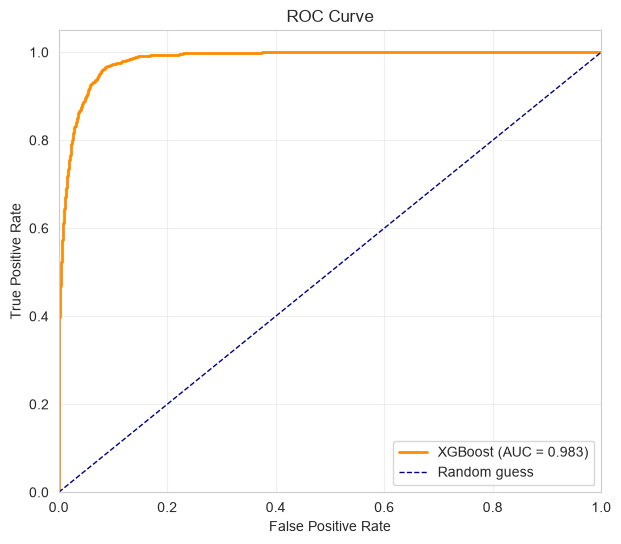

In [104]:
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"XGBoost (AUC = {area:.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Random guess")
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

#### Model Evaluation: Rank Order & KS Statistic

In [156]:
df_grouped = pd.DataFrame({})
df_grouped

""


In [157]:
pd.set_option('display.float_format', '{:.2f}'.format)

In [158]:
probabilities = best_model_logistic.predict_proba(X_test_encoded)[:, 1]

In [159]:
df_eval = pd.DataFrame({
    "default_truth": y_test,
    "default_probability": probabilities
})
df_eval.head(3)

,default_truth,default_probability
33553,0,0.00
9427,0,0.77
199,0,0.14


In [160]:
df_eval['decile'] = pd.qcut(df_eval['default_probability'], q=10, labels=False, duplicates='drop')
df_eval

,default_truth,default_probability,decile
33553,0,0.00,1
9427,0,0.77,8
199,0,0.14,7
12447,0,0.42,8
39489,0,0.00,5
...,...,...,...
9771,0,0.00,2
34737,0,0.00,1
30390,0,0.00,1
6797,0,0.00,1


In [161]:
df_grouped = df_eval.groupby('decile').apply(lambda x: pd.Series({
    'min_probability': x['default_probability'].min(),
    'max_probability': x['default_probability'].max(),
    'events': x['default_truth'].sum(),
    'non_events': x['default_truth'].count() - x['default_truth'].sum()
}))
df_grouped.reset_index(inplace=True)
df_grouped

,decile,min_probability,max_probability,events,non_events
0,0,0.00,0.00,0.00,1250.00
1,1,0.00,0.00,0.00,1250.00
2,2,0.00,0.00,0.00,1250.00
3,3,0.00,0.00,0.00,1249.00
4,4,0.00,0.00,0.00,1250.00
5,5,0.00,0.01,1.00,1249.00
6,6,0.01,0.03,2.00,1247.00
7,7,0.03,0.21,17.00,1233.00
8,8,0.21,0.82,169.00,1081.00
9,9,0.82,1.00,919.00,331.00


In [162]:
df_grouped['event_rate'] = 100 * df_grouped['events'] / (df_grouped['events'] + df_grouped['non_events'])
df_grouped['non_event_rate'] = 100 * df_grouped['non_events'] / (df_grouped['events'] + df_grouped['non_events'])
df_grouped

,decile,min_probability,max_probability,events,non_events,event_rate,non_event_rate
0,0,0.00,0.00,0.00,1250.00,0.00,100.00
1,1,0.00,0.00,0.00,1250.00,0.00,100.00
2,2,0.00,0.00,0.00,1250.00,0.00,100.00
3,3,0.00,0.00,0.00,1249.00,0.00,100.00
4,4,0.00,0.00,0.00,1250.00,0.00,100.00
5,5,0.00,0.01,1.00,1249.00,0.08,99.92
6,6,0.01,0.03,2.00,1247.00,0.16,99.84
7,7,0.03,0.21,17.00,1233.00,1.36,98.64
8,8,0.21,0.82,169.00,1081.00,13.52,86.48
9,9,0.82,1.00,919.00,331.00,73.52,26.48


In [163]:
df_grouped = df_grouped.sort_values(by='decile', ascending=False).reset_index(drop=True)
df_grouped

,decile,min_probability,max_probability,events,non_events,event_rate,non_event_rate
0,9,0.82,1.00,919.00,331.00,73.52,26.48
1,8,0.21,0.82,169.00,1081.00,13.52,86.48
2,7,0.03,0.21,17.00,1233.00,1.36,98.64
3,6,0.01,0.03,2.00,1247.00,0.16,99.84
4,5,0.00,0.01,1.00,1249.00,0.08,99.92
5,4,0.00,0.00,0.00,1250.00,0.00,100.00
6,3,0.00,0.00,0.00,1249.00,0.00,100.00
7,2,0.00,0.00,0.00,1250.00,0.00,100.00
8,1,0.00,0.00,0.00,1250.00,0.00,100.00
9,0,0.00,0.00,0.00,1250.00,0.00,100.00


In [164]:
df_grouped['cum_events'] = df_grouped['events'].cumsum()
df_grouped['non_cum_events'] = df_grouped['non_events'].cumsum()
df_grouped

,decile,min_probability,max_probability,events,non_events,event_rate,non_event_rate,cum_events,non_cum_events
0,9,0.82,1.00,919.00,331.00,73.52,26.48,919.00,331.00
1,8,0.21,0.82,169.00,1081.00,13.52,86.48,1088.00,1412.00
2,7,0.03,0.21,17.00,1233.00,1.36,98.64,1105.00,2645.00
3,6,0.01,0.03,2.00,1247.00,0.16,99.84,1107.00,3892.00
4,5,0.00,0.01,1.00,1249.00,0.08,99.92,1108.00,5141.00
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6391.00
6,3,0.00,0.00,0.00,1249.00,0.00,100.00,1108.00,7640.00
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8890.00
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10140.00
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11390.00


In [165]:
df_grouped['cum_event_rate'] = 100 * df_grouped['cum_events'] / df_grouped['events'].sum()
df_grouped['non_cum_event_rate'] = 100 * df_grouped['non_cum_events'] / df_grouped['non_events'].sum()
df_grouped

,decile,min_probability,max_probability,events,non_events,event_rate,non_event_rate,cum_events,non_cum_events,cum_event_rate,non_cum_event_rate
0,9,0.82,1.00,919.00,331.00,73.52,26.48,919.00,331.00,82.94,2.91
1,8,0.21,0.82,169.00,1081.00,13.52,86.48,1088.00,1412.00,98.19,12.40
2,7,0.03,0.21,17.00,1233.00,1.36,98.64,1105.00,2645.00,99.73,23.22
3,6,0.01,0.03,2.00,1247.00,0.16,99.84,1107.00,3892.00,99.91,34.17
4,5,0.00,0.01,1.00,1249.00,0.08,99.92,1108.00,5141.00,100.00,45.14
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6391.00,100.00,56.11
6,3,0.00,0.00,0.00,1249.00,0.00,100.00,1108.00,7640.00,100.00,67.08
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8890.00,100.00,78.05
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10140.00,100.00,89.03
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11390.00,100.00,100.00


In [166]:
df_grouped['KS'] = abs(df_grouped['cum_event_rate'] - df_grouped['non_cum_event_rate'])
df_grouped

,decile,min_probability,max_probability,events,non_events,event_rate,non_event_rate,cum_events,non_cum_events,cum_event_rate,non_cum_event_rate,KS
0,9,0.82,1.00,919.00,331.00,73.52,26.48,919.00,331.00,82.94,2.91,80.04
1,8,0.21,0.82,169.00,1081.00,13.52,86.48,1088.00,1412.00,98.19,12.40,85.80
2,7,0.03,0.21,17.00,1233.00,1.36,98.64,1105.00,2645.00,99.73,23.22,76.51
3,6,0.01,0.03,2.00,1247.00,0.16,99.84,1107.00,3892.00,99.91,34.17,65.74
4,5,0.00,0.01,1.00,1249.00,0.08,99.92,1108.00,5141.00,100.00,45.14,54.86
5,4,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,6391.00,100.00,56.11,43.89
6,3,0.00,0.00,0.00,1249.00,0.00,100.00,1108.00,7640.00,100.00,67.08,32.92
7,2,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,8890.00,100.00,78.05,21.95
8,1,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,10140.00,100.00,89.03,10.97
9,0,0.00,0.00,0.00,1250.00,0.00,100.00,1108.00,11390.00,100.00,100.00,0.00


In [176]:
gini_coefficient = 2 * area - 1

print("AUC:", area)
print("Gini Coefficient:", gini_coefficient)

AUC: 0.9829904945436335
Gini Coefficient: 0.965980989087267


#### Finalize the Model

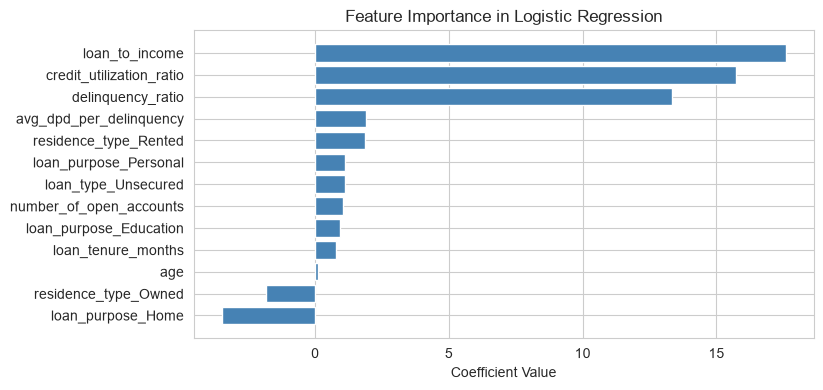

In [177]:
final_model = best_model_logistic

feature_importance = final_model.coef_[0]

# Create a DataFrame for easier handling
coef_df = pd.DataFrame(feature_importance, index=X_train_encoded.columns, columns=['Coefficients'])

# Sort the coefficients for better visualization
coef_df = coef_df.sort_values(by='Coefficients', ascending=True)

# Plotting
plt.figure(figsize=(8, 4))
plt.barh(coef_df.index, coef_df['Coefficients'], color='steelblue')
plt.xlabel('Coefficient Value')
plt.title('Feature Importance in Logistic Regression')
plt.show()

#### Save the Model

In [178]:
X_test_encoded.head()

,age,loan_tenure_months,number_of_open_accounts,credit_utilization_ratio,loan_to_income,delinquency_ratio,avg_dpd_per_delinquency,residence_type_Owned,residence_type_Rented,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_type_Unsecured
33553,0.35,0.53,0.33,0.12,0.26,0.04,0.90,True,False,True,False,False,False
9427,0.29,0.62,1.00,0.86,0.69,0.00,0.00,True,False,False,True,False,False
199,0.19,0.62,1.00,0.73,0.63,0.00,0.00,True,False,False,True,False,False
12447,0.19,0.19,0.67,0.91,0.19,0.00,0.00,False,True,False,False,False,False
39489,0.65,0.38,1.00,0.54,0.17,0.13,0.53,True,False,False,False,False,False


In [179]:
X_test_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [180]:
cols_to_scale

['age',
 'number_of_dependants',
 'years_at_current_address',
 'zipcode',
 'sanction_amount',
 'processing_fee',
 'gst',
 'net_disbursement',
 'loan_tenure_months',
 'principal_outstanding',
 'bank_balance_at_application',
 'number_of_open_accounts',
 'number_of_closed_accounts',
 'enquiry_count',
 'credit_utilization_ratio',
 'loan_to_income',
 'delinquency_ratio',
 'avg_dpd_per_delinquency']

In [181]:
X_train_encoded.columns

Index(['age', 'loan_tenure_months', 'number_of_open_accounts',
       'credit_utilization_ratio', 'loan_to_income', 'delinquency_ratio',
       'avg_dpd_per_delinquency', 'residence_type_Owned',
       'residence_type_Rented', 'loan_purpose_Education', 'loan_purpose_Home',
       'loan_purpose_Personal', 'loan_type_Unsecured'],
      dtype='str')

In [182]:
final_model = best_model_logistic

In [183]:
final_model.coef_, final_model.intercept_

(array([[ 0.09937012,  0.7621174 ,  1.02269839, 15.71407178, 17.58336156,
         13.33914004,  1.91638361, -1.85546411,  1.86056809,  0.91642   ,
         -3.48742737,  1.11278265,  1.11278265]]),
 array([-20.59272192]))

In [184]:
from joblib import dump

model_data = {
    'model': final_model,
    'features': X_train_encoded.columns,
    'scaler': scaler,
    'cols_to_scale': cols_to_scale
}

dump(model_data, './artifacts/model_data.joblib')

['./artifacts/model_data.joblib']